# Analytic probability gradients


This notebook validates analytic gradients against independent probability-only finite differences. It covers vacuum/constant-matter oscillation parameters, constant density and electron fraction, layered media, and continuously varying parameterized profiles sampled on a fixed grid.

The channel is muon-neutrino to electron-neutrino appearance, P(νμ → νe), a dimensionless probability. Flavor indices are `0 = electron`, `1 = muon`, `2 = tau`. The first scan uses L = 295 km and E = 0.6 GeV. Later examples use L = 1300 km and E = 0.8 GeV to make matter sensitivity more visible. Each plot states its medium, channel and baseline/energy.

Jacobian columns follow `parameterBasis`, including subsets and repeated references. Derivatives are physical: angles/phases in radians, density in g/cm³ and electron fraction dimensionless. Density and electron fraction enter through their product, proportional to electron number density; `MatterDensity` differentiates mass density at fixed Ye, not electron number density directly. There is no division by probability or fit-space scaling.

Probabilities and gradients share backend propagation kernels. These plots use NumPy double precision with explicit numerical tolerances; unit tests also cover Torch CPU and MPS. The MPS backend uses single precision and its existing CPU eigendecomposition fallback. Probability-only calls allocate no tangent arrays. Profile boundaries and layer widths remain fixed in every derivative.

In [8]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Allow execution from the repository root or notebooks directory.
repoRoot = Path.cwd()
if not (repoRoot / 'src').exists():
    repoRoot = repoRoot.parent
sys.path.insert(0, str(repoRoot / 'src'))

from nu_waves.models.mixing import Mixing
from nu_waves.models.spectrum import Spectrum
from nu_waves.hamiltonian import vacuum, matter
from nu_waves.propagation.oscillator import Oscillator, NeutrinoEventBatch
from nu_waves.propagation.gradient import MixingAngle, DiracPhase, MassSquaredDifference

parameterBasis = [MixingAngle(1, 2), MixingAngle(1, 3), MixingAngle(2, 3),
                  DiracPhase(1, 3), MassSquaredDifference(2, 1), MassSquaredDifference(3, 2)]
parameterNames = [r'$\theta_{12}$ [rad]', r'$\theta_{13}$ [rad]', r'$\theta_{23}$ [rad]',
                  r'$\delta_{CP}$ [rad]', r'$\Delta m^2_{21}$ [eV²]', r'$\Delta m^2_{32}$ [eV²]']
referenceValues = np.array([0.58725, 0.14819, 0.81341, -1.601, 7.53e-5, 2.509e-3])
scanWidths = [0.2, 0.07, 0.25, np.pi, 4e-5, 1e-3]
epsilons = [1e-6, 1e-6, 1e-6, 1e-6, 1e-9, 1e-9]
isAntiNu = False
emittedFlavor, detectedFlavor = 1, 0


matterDensity = 2.6  # g/cm³
electronFraction = 0.5


def makeOscillator(values, useMatter=False):
    mixing = Mixing(3, {(1, 2): values[0], (1, 3): values[1], (2, 3): values[2]},
                    {(1, 3): values[3]})
    spectrum = Spectrum(3, {(2, 1): values[4], (3, 2): values[5]})
    hamiltonian = (matter if useMatter else vacuum).Hamiltonian(mixing, spectrum, False)
    if useMatter:
        hamiltonian.set_constant_density(matterDensity, electronFraction)
    return Oscillator(hamiltonian)


events = NeutrinoEventBatch([295.], [0.6], [emittedFlavor], [detectedFlavor], [isAntiNu])
compiledEvents = makeOscillator(referenceValues).compileEvents(events)

MixingAngle(i=1, j=2): epsilon=1e-06, max absolute error=1.373e-10
MixingAngle(i=1, j=3): epsilon=1e-06, max absolute error=1.541e-10
MixingAngle(i=2, j=3): epsilon=1e-06, max absolute error=1.302e-10
DiracPhase(i=1, j=3): epsilon=1e-06, max absolute error=1.002e-10
MassSquaredDifference(i=2, j=1): epsilon=1e-09, max absolute error=1.494e-07
MassSquaredDifference(i=3, j=2): epsilon=1e-09, max absolute error=1.362e-07


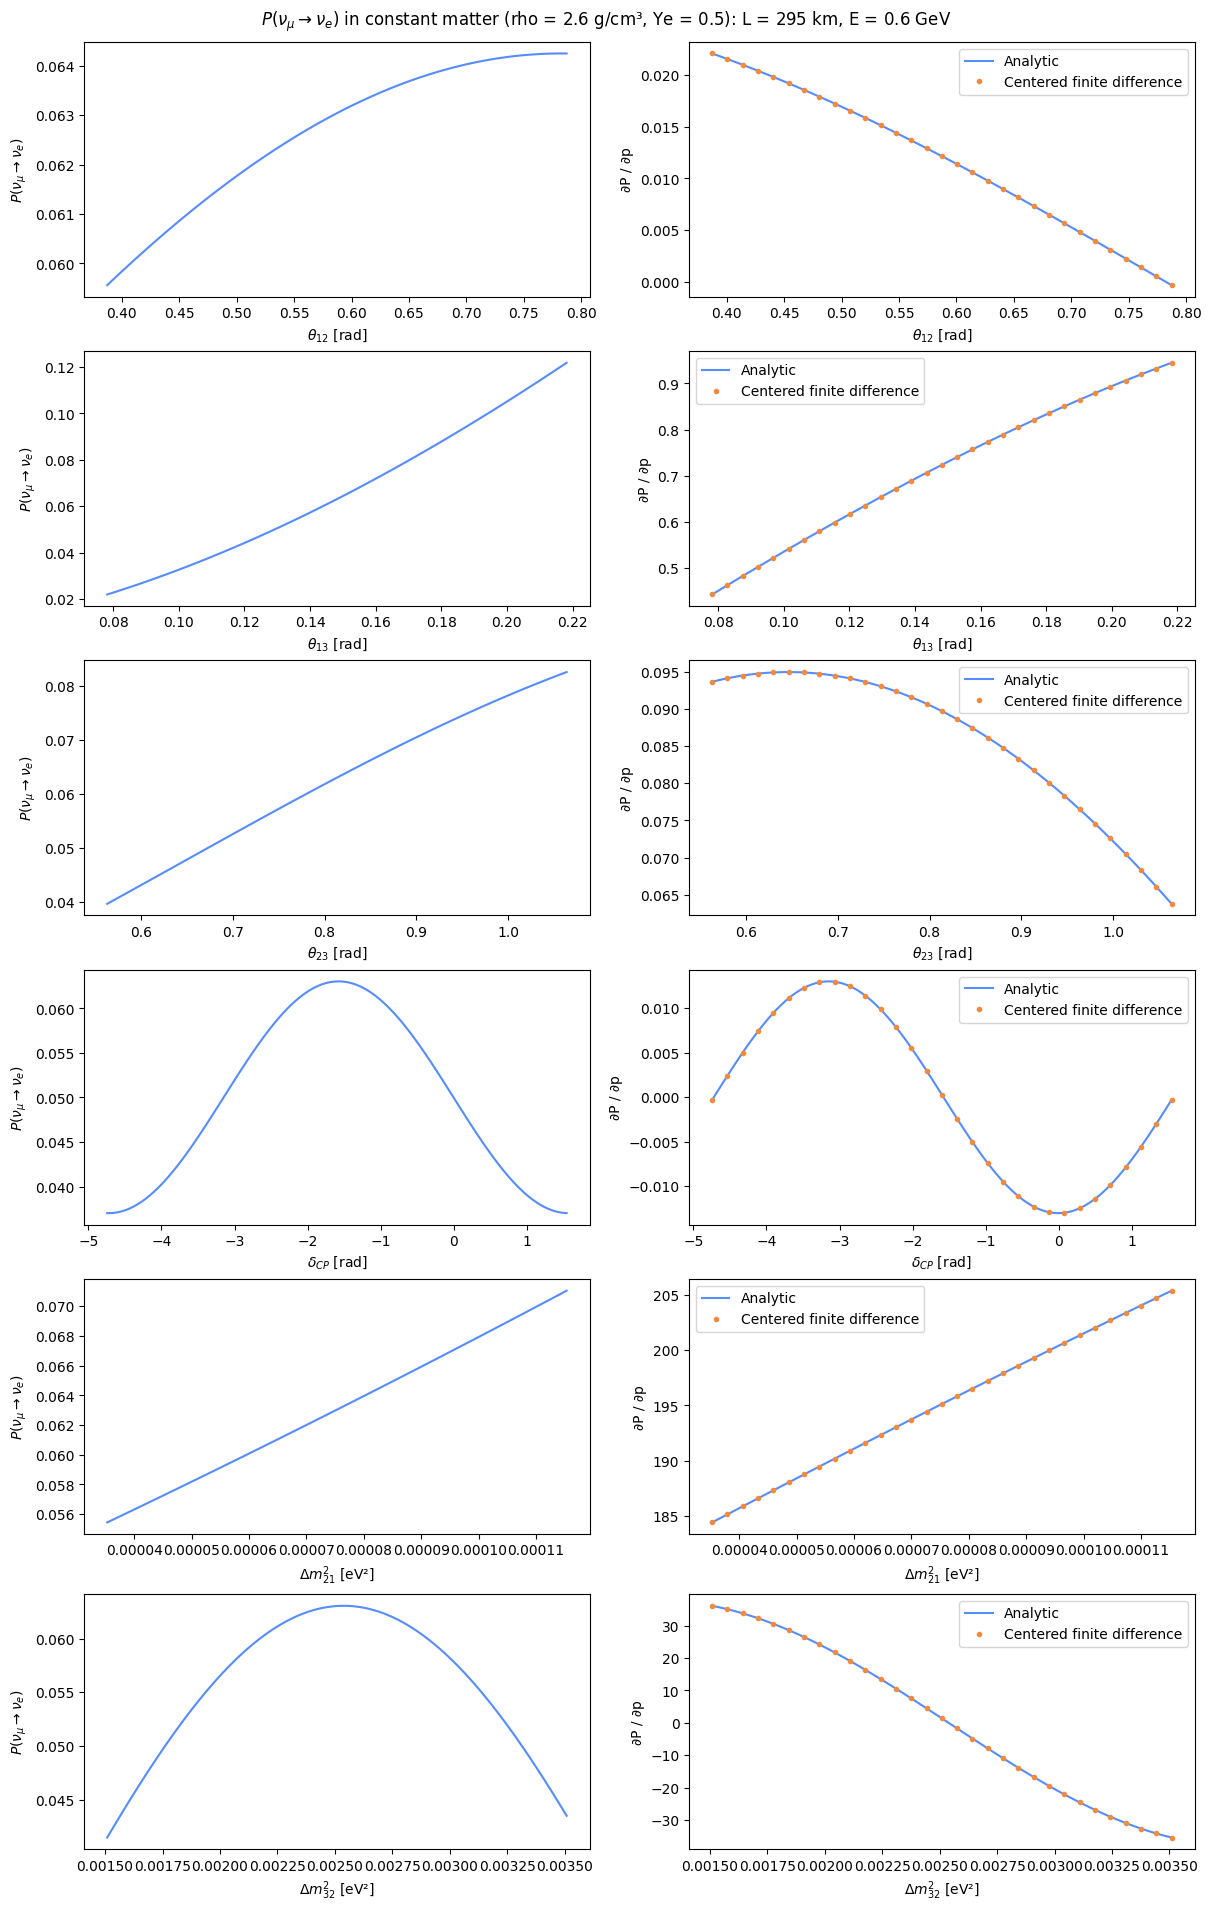

In [9]:
useMatter = True
slash = chr(92)
flavorLabels = [slash + 'nu_e', slash + 'nu_' + slash + 'mu', slash + 'nu_' + slash + 'tau']
if isAntiNu:
    flavorLabels = [slash + 'bar{' + label + '}' for label in flavorLabels]
channelLabel = flavorLabels[emittedFlavor] + ' ' + slash + 'to ' + flavorLabels[detectedFlavor]
probabilityLabel = '$P(' + channelLabel + ')$'
fig, axes = plt.subplots(6, 2, figsize=(12, 19), constrained_layout=True)
for column, (parameter, width, epsilon) in enumerate(zip(parameterBasis, scanWidths, epsilons)):
    scanValues = np.linspace(referenceValues[column] - width, referenceValues[column] + width, 121)
    probabilities, analytic, numerical = [], [], []
    for value in scanValues:
        values = referenceValues.copy()
        values[column] = value
        oscillator = makeOscillator(values, useMatter=useMatter)
        probability, gradient = oscillator.probability(compiledEvents, parameterBasis=[parameter])
        probabilities.append(probability[0])
        analytic.append(gradient[0, 0])
        plus, minus = values.copy(), values.copy()
        plus[column] += epsilon
        minus[column] -= epsilon
        numerical.append((makeOscillator(plus, useMatter=useMatter).probability(compiledEvents)[0] -
                          makeOscillator(minus, useMatter=useMatter).probability(compiledEvents)[0]) / (2 * epsilon))
    analytic, numerical = np.asarray(analytic), np.asarray(numerical)
    np.testing.assert_allclose(analytic, numerical, rtol=2e-5, atol=2e-6)
    axes[column, 0].plot(scanValues, probabilities)
    axes[column, 0].set(ylabel=probabilityLabel, xlabel=parameterNames[column])
    axes[column, 1].plot(scanValues, analytic, label='Analytic')
    axes[column, 1].plot(scanValues[::4], numerical[::4], '.', label='Centered finite difference')
    axes[column, 1].set(ylabel='∂P / ∂p', xlabel=parameterNames[column])
    axes[column, 1].legend()
    print(f'{parameter}: epsilon={epsilon:g}, max absolute error={np.max(np.abs(analytic - numerical)):.3e}')
mediumLabel = f'constant matter (rho = {matterDensity:g} g/cm³, Ye = {electronFraction:g})' if useMatter else 'vacuum'
fig.suptitle(probabilityLabel + ' in ' + mediumLabel + ': L = 295 km, E = 0.6 GeV')
plt.show()

In [10]:
# Additional matter examples use a longer baseline for visible sensitivity.
from nu_waves.propagation.gradient import MatterDensity, ElectronFraction, ProfileParameter
from nu_waves.matter.ParameterizedProfile import ParameterizedMatterProfile

diagnosticEvents = NeutrinoEventBatch([1300.], [0.8], [1], [0], [False])


def makeMatter(values=referenceValues, profile=None, rho=2.6, ye=0.5):
    oscillator = makeOscillator(values, useMatter=True)
    oscillator.hamiltonian.set_constant_density(rho, ye)
    if profile is not None:
        oscillator.hamiltonian.set_matter_profile(profile)
    return oscillator


def validateScans(specifications, title):
    # Each factory rebuilds the physical model at the perturbed parameter value.
    fig, axes = plt.subplots(len(specifications), 2, figsize=(12, 3.2 * len(specifications)),
                             squeeze=False, constrained_layout=True)
    for row, (label, grid, step, parameter, factory) in enumerate(specifications):
        probabilities, analytic, numerical = [], [], []
        for value in grid:
            oscillator = factory(value)
            probability, gradient = oscillator.probability(diagnosticEvents, parameterBasis=[parameter])
            np.testing.assert_allclose(probability, oscillator.probability(diagnosticEvents), atol=1e-13)
            probabilities.append(probability[0])
            analytic.append(gradient[0, 0])
            def shifted(offset):
                return factory(value + offset * step).probability(diagnosticEvents)[0]
            numerical.append((shifted(-2) - 8*shifted(-1) + 8*shifted(1) - shifted(2)) / (12*step))
        analytic, numerical = np.asarray(analytic), np.asarray(numerical)
        np.testing.assert_allclose(analytic, numerical, rtol=3e-5, atol=3e-7)
        axes[row, 0].plot(grid, probabilities)
        axes[row, 0].set(xlabel=label, ylabel='P(νμ → νe)')
        axes[row, 1].plot(grid, analytic, label='Analytic')
        axes[row, 1].plot(grid[::3], numerical[::3], '.', label='Finite difference (order 4)')
        axes[row, 1].set(xlabel=label, ylabel='∂P / ∂parameter')
        axes[row, 1].legend()
        print(f'{title}, {label}: step={step:g}, max absolute error={np.max(np.abs(analytic - numerical)):.3e}')
    fig.suptitle(title + ': νμ → νe, L = 1300 km, E = 0.8 GeV')
    plt.show()

## Constant matter: density and electron fraction

The first figure above scans the six oscillation parameters in constant matter (set `useMatter=False` for vacuum). Here we vary mass density rho at fixed Ye, then Ye at fixed rho. The potential is proportional to rho × Ye. These are partial derivatives with respect to different physical coordinates; neither divides by the probability. The product identity is checked below.

Constant matter, rho [g/cm³]: step=0.001, max absolute error=2.252e-13
Constant matter, Ye: step=0.001, max absolute error=2.597e-13


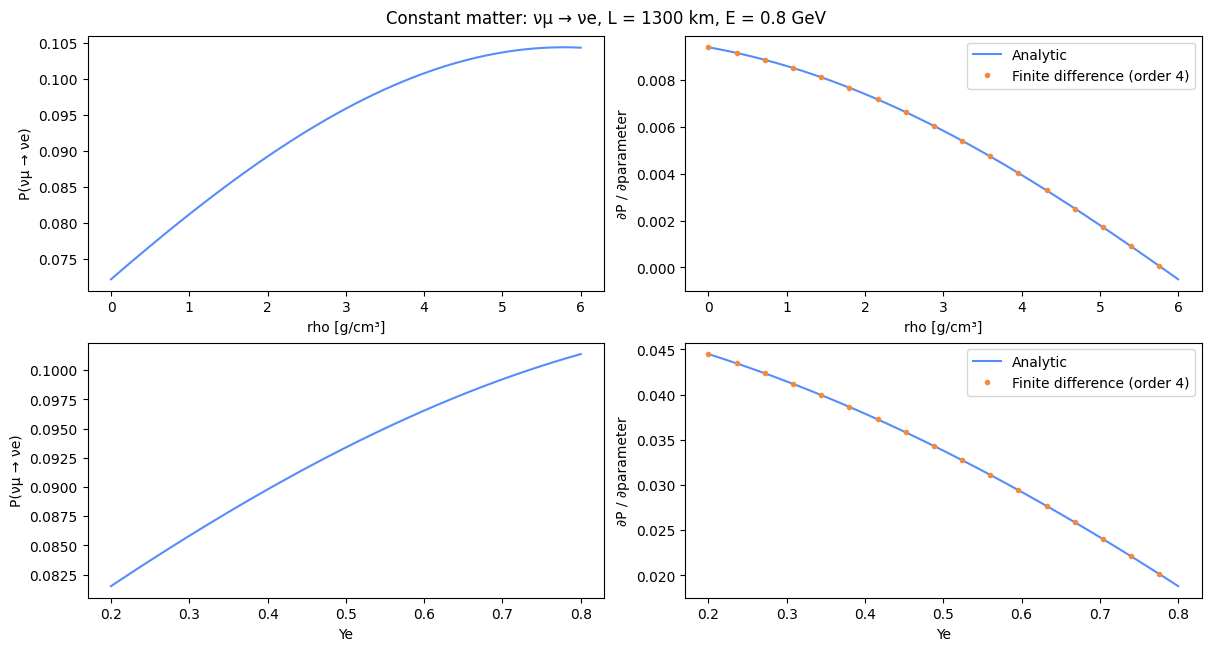

rho * dP/drho = Ye * dP/dYe: passed


In [11]:
validateScans([
    ('rho [g/cm³]', np.linspace(0., 6., 51), 1e-3, MatterDensity(), lambda value: makeMatter(rho=value)),
    ('Ye', np.linspace(.2, .8, 51), 1e-3, ElectronFraction(), lambda value: makeMatter(ye=value)),
], 'Constant matter')

_, matterGradient = makeMatter().probability(diagnosticEvents,
    parameterBasis=[MatterDensity(), ElectronFraction()])
np.testing.assert_allclose(2.6 * matterGradient[:, 0], .5 * matterGradient[:, 1], atol=1e-13)
print('rho * dP/drho = Ye * dP/dYe: passed')

## Layered matter: oscillation and local matter parameters

Two layers have densities [2.6, 4.1] g/cm³, electron fractions [0.5, 0.47], and lengths [40%, 60%] of the baseline. The first scan changes theta23 in both layers; the next two change only the indicated layer. Layer indices start at zero. The same propagation supports `MatterProfile.from_segments` with fixed lengths in km.

Two-layer matter, theta23 [rad]: step=0.001, max absolute error=2.751e-13
Two-layer matter, rho, layer 0 [g/cm³]: step=0.001, max absolute error=1.607e-13
Two-layer matter, Ye, layer 1: step=0.001, max absolute error=1.496e-13


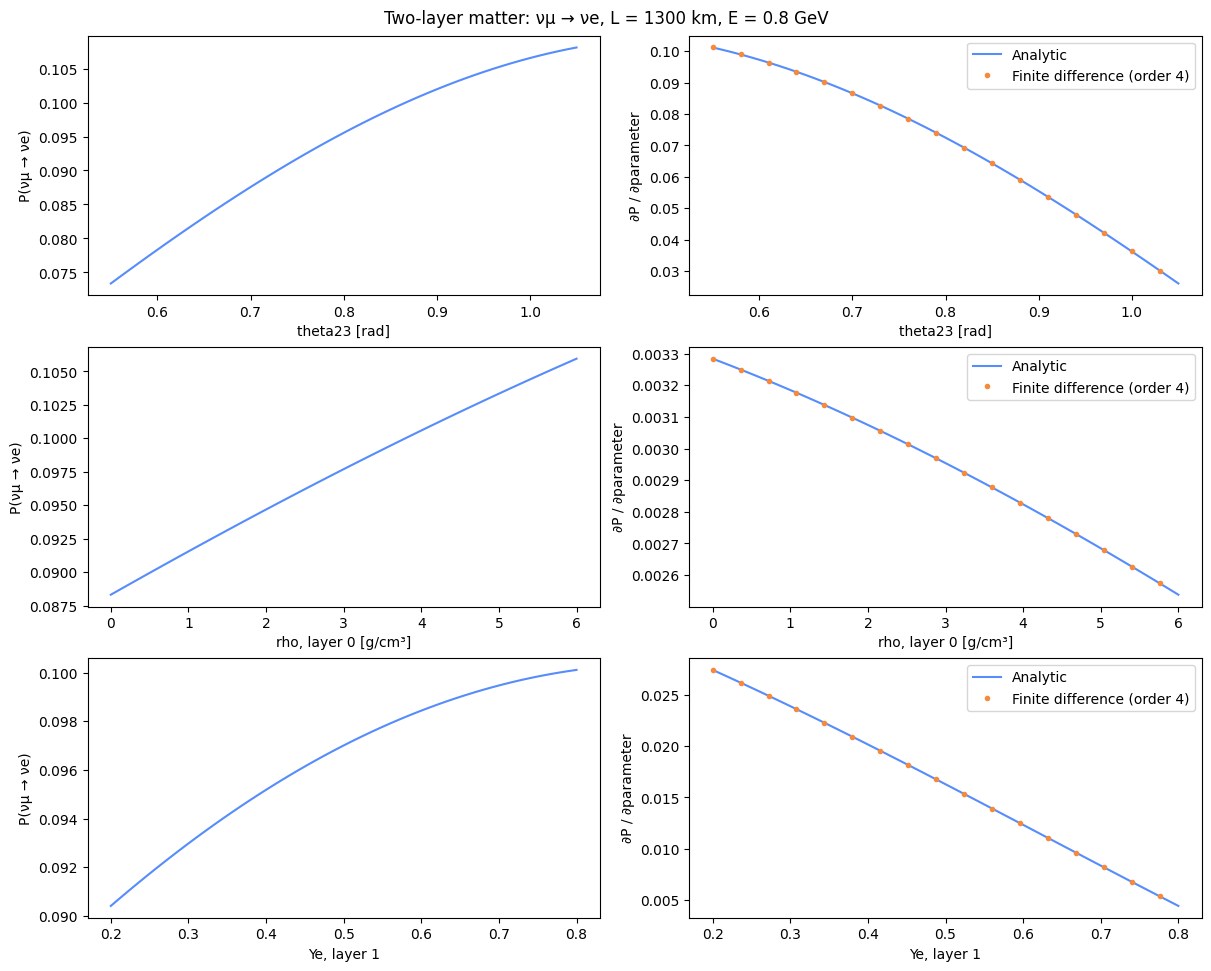

Layered probability and gradient conservation for neutrinos/antineutrinos: passed


In [12]:
def makeLayered(theta23=referenceValues[2], rho0=2.6, ye1=.47):
    values = referenceValues.copy()
    values[2] = theta23
    profile = matter.MatterProfile.from_fractions([rho0, 4.1], [.5, ye1], [.4, .6])
    return makeMatter(values, profile=profile)


validateScans([
    ('theta23 [rad]', np.linspace(.55, 1.05, 51), 1e-3, MixingAngle(2, 3), lambda value: makeLayered(theta23=value)),
    ('rho, layer 0 [g/cm³]', np.linspace(0., 6., 51), 1e-3, MatterDensity(0), lambda value: makeLayered(rho0=value)),
    ('Ye, layer 1', np.linspace(.2, .8, 51), 1e-3, ElectronFraction(1), lambda value: makeLayered(ye1=value)),
], 'Two-layer matter')

# Conservation includes both neutrino and antineutrino final-state channels.
allChannels = NeutrinoEventBatch(np.full(6, 1300.), np.full(6, .8), np.ones(6, dtype=int),
                                np.tile(np.arange(3), 2), np.repeat([False, True], 3))
probabilities, gradients = makeLayered().probability(allChannels,
    parameterBasis=[MixingAngle(2, 3), MatterDensity(0), ElectronFraction(1)])
np.testing.assert_allclose(probabilities.reshape(2, 3).sum(axis=1), 1., atol=1e-13)
np.testing.assert_allclose(gradients.reshape(2, 3, 3).sum(axis=1), 0., atol=1e-12)
print('Layered probability and gradient conservation for neutrinos/antineutrinos: passed')

## Continuously varying, parameterized profile

Let x be the fraction of the baseline, from 0 to 1. We sample rho(x) = scale × (2.6 + slope × x) and Ye(x) = ye at fixed layer midpoints. The density slope is in g/cm³, while scale and ye are dimensionless. The supplied analytic callbacks define how each layer changes with these global parameters. `ProfileParameter` requests a global derivative directly, without returning one event column per layer.

Each scan uses 24 fixed layers. Finite differences rebuild the sampled profile at shifted parameter values. This checks derivatives of the discretized model; the final convergence plot separately checks its approximation to the continuous profile. Parameter changes require a new profile snapshot. Omitted callback dictionary keys mean zero dependence; every requested profile parameter must have an explicit derivative in at least one callback.

Variable density (24 layers), Density normalization: step=0.001, max absolute error=9.383e-13
Variable density (24 layers), Density slope [g/cm³]: step=0.001, max absolute error=6.430e-13
Variable density (24 layers), Ye: step=0.001, max absolute error=4.731e-13


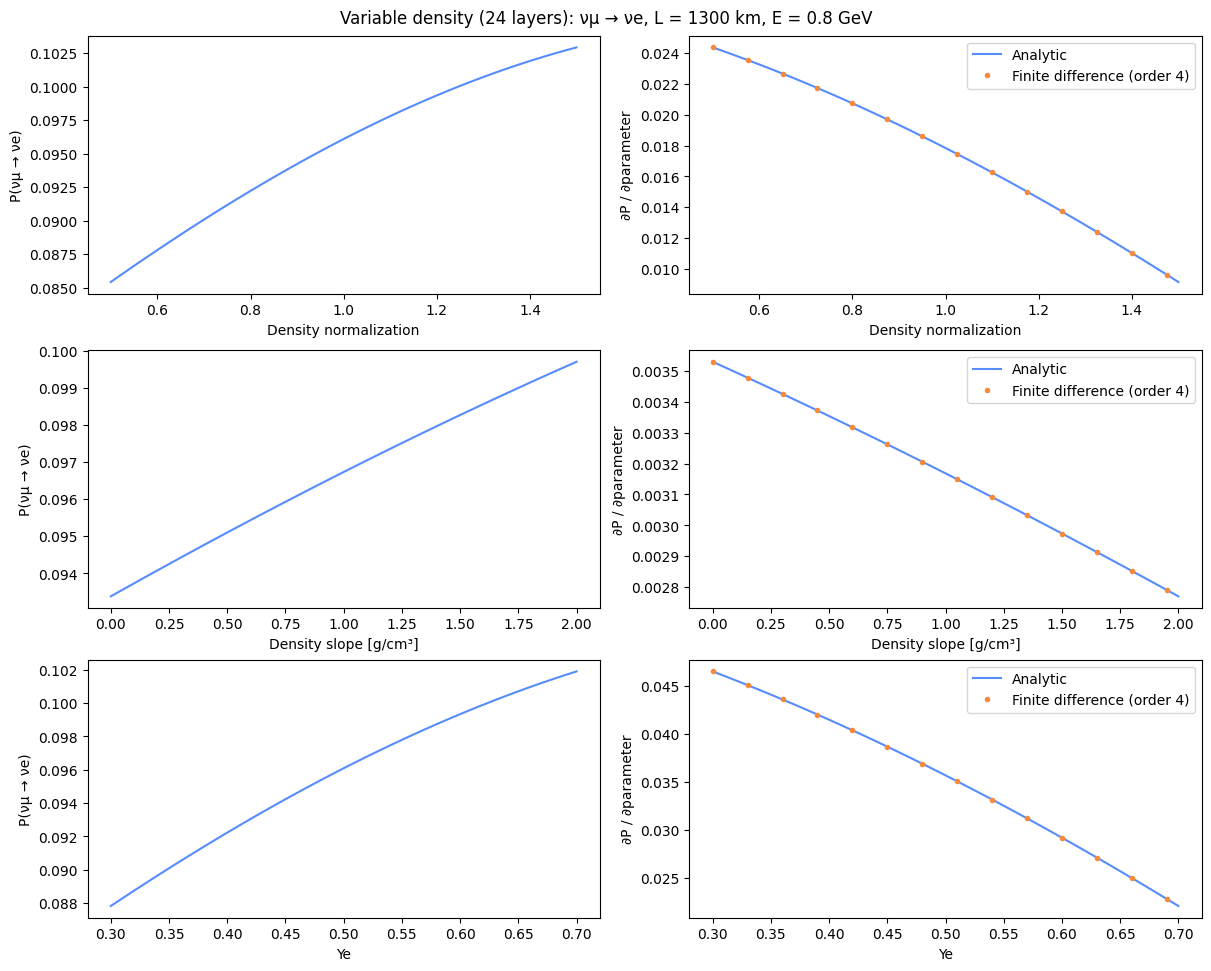

In [13]:
def makeContinuous(scale=1., slope=.8, ye=.5, nLayers=24):
    profile = ParameterizedMatterProfile(
        edges=np.linspace(0., 1., nLayers + 1),
        parameters=dict(scale=scale, slope=slope, ye=ye),
        density=lambda x, p: p['scale'] * (2.6 + p['slope'] * x),
        electronFraction=lambda x, p: p['ye'],
        densityGradient=lambda x, p: {'scale': 2.6 + p['slope'] * x, 'slope': p['scale'] * x},
        electronFractionGradient=lambda x, p: {'ye': 1.},
    )
    return makeMatter(profile=profile)


validateScans([
    ('Density normalization', np.linspace(.5, 1.5, 41), 1e-3, ProfileParameter('scale'), lambda value: makeContinuous(scale=value)),
    ('Density slope [g/cm³]', np.linspace(0., 2., 41), 1e-3, ProfileParameter('slope'), lambda value: makeContinuous(slope=value)),
    ('Ye', np.linspace(.3, .7, 41), 1e-3, ProfileParameter('ye'), lambda value: makeContinuous(ye=value)),
], 'Variable density (24 layers)')

Global profile gradient equals the weighted sum of layer gradients: passed


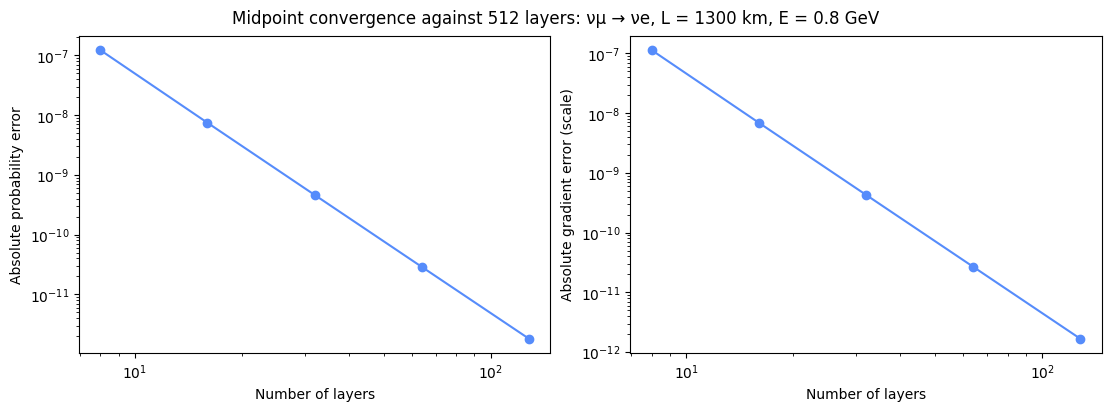

Both probability and gradient converge as the grid is refined.


In [14]:
# Check the global chain rule against a Jacobian of independent layer values.
oscillator = makeContinuous(nLayers=24)
_, globalGradient = oscillator.probability(diagnosticEvents, parameterBasis=[ProfileParameter('scale')])
_, localGradient = oscillator.probability(diagnosticEvents,
    parameterBasis=[MatterDensity(k) for k in range(24)])
dRho, _ = oscillator.hamiltonian._matter_profile.parameterGradients({'scale'})['scale']
np.testing.assert_allclose(globalGradient[:, 0], localGradient @ dRho, atol=1e-13)
print('Global profile gradient equals the weighted sum of layer gradients: passed')

layerCounts = [8, 16, 32, 64, 128]
referenceP, referenceG = makeContinuous(nLayers=512).probability(diagnosticEvents,
    parameterBasis=[ProfileParameter('scale')])
probabilityErrors, gradientErrors = [], []
for count in layerCounts:
    probability, gradient = makeContinuous(nLayers=count).probability(diagnosticEvents,
        parameterBasis=[ProfileParameter('scale')])
    probabilityErrors.append(abs(probability[0] - referenceP[0]))
    gradientErrors.append(abs(gradient[0, 0] - referenceG[0, 0]))
assert np.all(np.diff(probabilityErrors) < 0)
assert np.all(np.diff(gradientErrors) < 0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].loglog(layerCounts, probabilityErrors, 'o-')
axes[0].set(xlabel='Number of layers', ylabel='Absolute probability error')
axes[1].loglog(layerCounts, gradientErrors, 'o-')
axes[1].set(xlabel='Number of layers', ylabel='Absolute gradient error (scale)')
fig.suptitle('Midpoint convergence against 512 layers: νμ → νe, L = 1300 km, E = 0.8 GeV')
plt.show()
print('Both probability and gradient converge as the grid is refined.')